# Processing Dramv annotations

In [1]:
import pandas as pd

def rename_scaffold(scaffold):
    return scaffold.split("||")[0]


dramv = pd.read_csv("/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/raw_tables/annotations.tsv", sep='\t') # Was not uploaded to github beacuse it was too big
viral_list = pd.read_csv("/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/01_process_votus/tables/rel_abund/votus_dataset1_TMM_rel_abund.tsv", sep='\t', header=None)[0].tolist()

dramv['scaffold'] = dramv['scaffold'].apply(rename_scaffold)
dramv = dramv[dramv['scaffold'].isin(viral_list)]


dramv = dramv[['scaffold','kegg_hit','viral_hit','pfam_hits','vogdb_hits']]
dramv= dramv.set_index('scaffold')
# Drop rows where all elements are NaN
dramv = dramv.dropna(how='all')
dramv = dramv.reset_index()
dramv.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/dramv_results.tsv',sep='\t',index=False)
dramv

,scaffold,kegg_hit,viral_hit,pfam_hits,vogdb_hits
0,AP1_NODE_1015_length_28855_cov_2.442704,ferrous iron transport protein A,NaN,FeoA domain [PF04023.17],NaN
1,AP1_NODE_1015_length_28855_cov_2.442704,NaN,NaN,NaN,REFSEQ hypothetical cyanophage protein; Xu
2,AP1_NODE_1015_length_28855_cov_2.442704,NaN,NaN,NaN,REFSEQ hypothetical protein; Xu
3,AP1_NODE_1015_length_28855_cov_2.442704,NaN,NaN,NaN,REFSEQ hypothetical protein; Xu
4,AP1_NODE_1015_length_28855_cov_2.442704,NaN,NaN,NaN,REFSEQ hypothetical protein; Xu
...,...,...,...,...,...
83534,PP5_NODE_95_length_56068_cov_2.662859,NaN,YP_009604040.1 terminase large subunit [Arthro...,"Terminase large subunit, T4likevirus-type, N-t...",sp|Q05219|VG13_BPML5 Gene 13 protein; Xu
83535,PP5_NODE_95_length_56068_cov_2.662859,NaN,YP_010078228.1 terminase small subunit [Ralsto...,NaN,NaN
83536,PP5_NODE_95_length_56068_cov_2.662859,NaN,NaN,NaN,REFSEQ hypothetical protein; Xu
83537,PP5_NODE_95_length_56068_cov_2.662859,NaN,YP_010078216.1 hypothetical protein KMC44_gp62...,NaN,REFSEQ hypothetical protein; Xu


In [2]:
dramv['final_annotation'] = dramv['viral_hit'].fillna(dramv['pfam_hits'].fillna(dramv['vogdb_hits'].fillna(dramv['kegg_hit'])))
dramv = dramv[['scaffold','final_annotation']]
dramv

,scaffold,final_annotation
0,AP1_NODE_1015_length_28855_cov_2.442704,FeoA domain [PF04023.17]
1,AP1_NODE_1015_length_28855_cov_2.442704,REFSEQ hypothetical cyanophage protein; Xu
2,AP1_NODE_1015_length_28855_cov_2.442704,REFSEQ hypothetical protein; Xu
3,AP1_NODE_1015_length_28855_cov_2.442704,REFSEQ hypothetical protein; Xu
4,AP1_NODE_1015_length_28855_cov_2.442704,REFSEQ hypothetical protein; Xu
...,...,...
83534,PP5_NODE_95_length_56068_cov_2.662859,YP_009604040.1 terminase large subunit [Arthro...
83535,PP5_NODE_95_length_56068_cov_2.662859,YP_010078228.1 terminase small subunit [Ralsto...
83536,PP5_NODE_95_length_56068_cov_2.662859,REFSEQ hypothetical protein; Xu
83537,PP5_NODE_95_length_56068_cov_2.662859,YP_010078216.1 hypothetical protein KMC44_gp62...


# Extract annotations by VOGDB classification

In [3]:
def get_sample_name(contig_id):
    return contig_id.split("_")[0]

def define_city(sample):
    if sample.startswith("AP"):
        return "Altamira"
    elif sample.startswith("BP"):
        return "Bragança"
    elif sample.startswith("MP"):
        return "Maraba"
    elif sample.startswith("PP"):
        return "Paragominas"

vmag_stats = pd.read_csv("/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/raw_tables/vMAG_stats.tsv", sep='\t')
vmag_stats = vmag_stats.rename(columns={'Unnamed: 0':'contig_id'})
vmag_stats = vmag_stats[['contig_id', 'Viral replication genes', 'Viral hypothetical genes', 'Viral genes with unknown function',
             'Viral genes with host benefits', 'Viral genes with viral benefits', 'Viral structure genes']]
vmag_stats['contig_id'] = vmag_stats['contig_id'].apply(rename_scaffold)
vmag_stats['sample'] = vmag_stats['contig_id'].apply(get_sample_name)

vmag_stats['city'] = vmag_stats['sample'].apply(define_city)
vmag_stats = vmag_stats[vmag_stats['contig_id'].isin(viral_list)]
vmag_stats


,contig_id,Viral replication genes,Viral hypothetical genes,Viral genes with unknown function,Viral genes with host benefits,Viral genes with viral benefits,Viral structure genes,sample,city
7,AP1_NODE_1015_length_28855_cov_2.442704,0.0,24.0,11.0,3.0,0.0,0.0,AP1,Altamira
8,AP1_NODE_1019_length_28805_cov_4.940442,0.0,46.0,2.0,2.0,0.0,0.0,AP1,Altamira
13,AP1_NODE_1026_length_28694_cov_1.324710,0.0,32.0,4.0,0.0,0.0,1.0,AP1,Altamira
45,AP1_NODE_1087_length_27770_cov_1.242123,0.0,41.0,3.0,0.0,0.0,0.0,AP1,Altamira
51,AP1_NODE_10_length_320914_cov_6.491204,1.0,335.0,15.0,24.0,1.0,2.0,AP1,Altamira
...,...,...,...,...,...,...,...,...,...
39677,PP5_NODE_924_length_15762_cov_1.839591,0.0,22.0,1.0,2.0,0.0,0.0,PP5,Paragominas
39694,PP5_NODE_94_length_56131_cov_2.043533,1.0,49.0,10.0,10.0,0.0,0.0,PP5,Paragominas
39696,PP5_NODE_953_length_15547_cov_2.636252,1.0,20.0,0.0,6.0,1.0,1.0,PP5,Paragominas
39697,PP5_NODE_954_length_15543_cov_1.573560,0.0,22.0,4.0,0.0,0.0,1.0,PP5,Paragominas


In [4]:
vmag_stats_by_city = vmag_stats.drop(columns=['contig_id', 'sample'])
vmag_stats_by_city = vmag_stats_by_city.groupby('city').sum().reset_index()
vmag_stats_by_city = vmag_stats_by_city.T
vmag_stats_by_city

,0,1,2,3
city,Altamira,Bragança,Maraba,Paragominas
Viral replication genes,634.0,76.0,1133.0,177.0
Viral hypothetical genes,47868.0,11442.0,104936.0,12508.0
Viral genes with unknown function,8484.0,1972.0,16008.0,2186.0
Viral genes with host benefits,5089.0,1065.0,10003.0,1433.0
Viral genes with viral benefits,73.0,30.0,142.0,26.0
Viral structure genes,822.0,201.0,1530.0,228.0


/MP_Data/database/rgi/wildcard/custom_tmp/ipykernel_3303244/2930489259.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dramv['sample'] = dramv['scaffold'].apply(get_sample_name)
/MP_Data/database/rgi/wildcard/custom_tmp/ipykernel_3303244/2930489259.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dramv['city'] = dramv['sample'].apply(define_city)
/MP_Data/mambaforge/envs/bioinfokit/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .

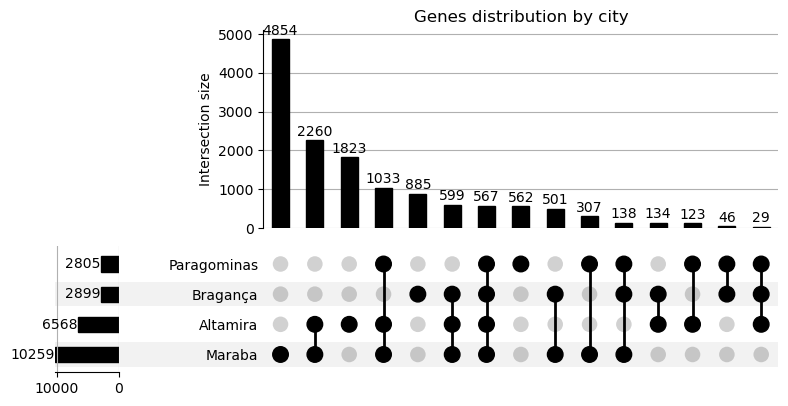

In [5]:
import pandas as pd
from upsetplot import UpSet, from_contents
import matplotlib.pyplot as plt


dramv['sample'] = dramv['scaffold'].apply(get_sample_name)
dramv['city'] = dramv['sample'].apply(define_city)


grouped = dramv.groupby('city')['final_annotation'].apply(set)


sample_sets = grouped.to_dict()

upset_data = from_contents(sample_sets)


UpSet(upset_data, show_counts=True, sort_by='cardinality').plot()
plt.title("Genes distribution by city")
plt.show()


# Refined annotation categorization

In [6]:
functional_categories = {
    "structural": [
        "head",
        "capsid",
        "tail",
        "baseplate",
        "fiber",
        "sheath",
        "collar",
        "neck",
        "spike",
        "plate",
        "tube",
        "connector",
        "polyprotein",
        "scaffold",
        "interna",
        "coat",
        "structur",
        "inner",
        "assembl",
        "adsorp",
        "attach",
        "envelop",
        "tape",
        "virion",
    ],
    "packaging": [
        "terminase",
        "portal",
        "packag",
    ],
    "exit": [
        "lysis",
        "holin",
        "spanin",
        "Rz",
        "lysin",
        "lysozyme",
        "peptidoglyc",
        "muram",
        "Virion export",
        "budd",
    ],
    "integration": [
        "integra",
        "transpos",
        "excision",
    ],
    "gene expression": [
        "DNA-directed RNA pol",
        "sigma",
        "tRNA",
        "RNA[- ]binding",
        "mRNA",
        "RNA[- ](lig|2'-phospho|silenc|helic|mediat|splic)",
        "RNAP",
        "transcrip",
        "transla",
    ],
    "anti-host defense": [
        "methyl",
        "restri",
        "modif",
        "CRISPR",
        "RNA-guided DNA endonuclease",
        "apoptos",
        "rII[AB $]",
    ],
    "replication": [
        "DNA",
        "repl",
        "RNA[- ]dep",
        "RNA[- ]directed",
        "polyprotein",
        "nucl",
        "d[ATCG]TP",
        "thymid",
        "Phosphoribosylformylglycinamidine",
        "puri",
        "pyrimid",
    ],
    "unknown": [
        "hypoth",
        "uncharacter",
        "unclass",
        "unident",
        "unknown",
        "DUF",
        "REFSEQ protein",
    ],
}



def define_annot_function(annotation):
    for index, (key, value) in enumerate(functional_categories.items()):
        for category in value:
            if category in annotation:
                return key
            
            
#categorizing the dramv tabel into more refined categories
dramv['Category'] = dramv['final_annotation'].apply(define_annot_function)
dramv['Category'] = dramv['Category'].fillna('unknown')
dramv

/MP_Data/database/rgi/wildcard/custom_tmp/ipykernel_3303244/262686627.py:104: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dramv['Category'] = dramv['final_annotation'].apply(define_annot_function)
/MP_Data/database/rgi/wildcard/custom_tmp/ipykernel_3303244/262686627.py:105: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dramv['Category'] = dramv['Category'].fillna('unknown')


,scaffold,final_annotation,sample,city,Category
0,AP1_NODE_1015_length_28855_cov_2.442704,FeoA domain [PF04023.17],AP1,Altamira,unknown
1,AP1_NODE_1015_length_28855_cov_2.442704,REFSEQ hypothetical cyanophage protein; Xu,AP1,Altamira,unknown
2,AP1_NODE_1015_length_28855_cov_2.442704,REFSEQ hypothetical protein; Xu,AP1,Altamira,unknown
3,AP1_NODE_1015_length_28855_cov_2.442704,REFSEQ hypothetical protein; Xu,AP1,Altamira,unknown
4,AP1_NODE_1015_length_28855_cov_2.442704,REFSEQ hypothetical protein; Xu,AP1,Altamira,unknown
...,...,...,...,...,...
83534,PP5_NODE_95_length_56068_cov_2.662859,YP_009604040.1 terminase large subunit [Arthro...,PP5,Paragominas,packaging
83535,PP5_NODE_95_length_56068_cov_2.662859,YP_010078228.1 terminase small subunit [Ralsto...,PP5,Paragominas,packaging
83536,PP5_NODE_95_length_56068_cov_2.662859,REFSEQ hypothetical protein; Xu,PP5,Paragominas,unknown
83537,PP5_NODE_95_length_56068_cov_2.662859,YP_010078216.1 hypothetical protein KMC44_gp62...,PP5,Paragominas,unknown


# Refined categories by city

In [7]:
cat_by_city = dramv[['city','Category']]
cat_by_city = cat_by_city.groupby('city').value_counts()
cat_by_city = cat_by_city.to_frame()
cat_by_city = cat_by_city.reset_index()
cat_by_city 

,city,Category,count
0,Altamira,unknown,15883
1,Altamira,structural,3294
2,Altamira,replication,2917
3,Altamira,packaging,977
4,Altamira,anti-host defense,418
5,Altamira,gene expression,350
6,Altamira,exit,279
7,Altamira,integration,130
8,Bragança,unknown,3110
9,Bragança,structural,857


# Refined categories by sample

In [9]:
cat_by_sample = dramv[['Category','sample']]
cat_by_sample = cat_by_sample.groupby('sample').value_counts()
cat_by_sample = cat_by_sample.to_frame()
cat_by_sample = cat_by_sample.reset_index()
cat_by_sample = cat_by_sample.pivot(index='sample', columns='Category', values='count')
cat_by_sample = cat_by_sample.reset_index()
cat_by_sample.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/annotations_general.tsv',sep='\t',index=False)
cat_by_sample

Category,sample,anti-host defense,exit,gene expression,integration,packaging,replication,structural,unknown
0,AP1,63,36,41,11,112,365,362,2037
1,AP2,74,45,89,29,198,603,668,3375
2,AP3,79,47,65,31,196,611,617,3248
3,AP4,54,34,26,20,107,350,394,1812
4,AP5,148,117,129,39,364,988,1253,5411
5,BP1,60,14,12,11,85,123,161,699
6,BP2,25,23,11,13,98,153,219,893
7,BP3,13,11,9,8,54,57,133,428
8,BP4,26,50,24,22,70,103,295,922
9,BP5,12,8,4,2,16,47,49,168


In [10]:
cat_by_sample.sum()

Category
sample               AP1AP2AP3AP4AP5BP1BP2BP3BP4BP5MP1MP2MP3MP4MP5P...
anti-host defense                                                 1585
exit                                                               996
gene expression                                                   1111
integration                                                        588
packaging                                                         3426
replication                                                       9891
structural                                                       11156
unknown                                                          54786
dtype: object

# Analysing the AMGs

In [11]:
pamgs = pd.read_csv("/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/raw_tables/amg_summary.tsv", sep='\t')

amgs = pamgs[pamgs['gene_id'].notna()]
#amgs = amgs[amgs['auxiliary_score'] != 3]
amgs = amgs[['scaffold','category','header','subheader','gene_id','gene_description']]
amgs['scaffold'] = amgs['scaffold'].apply(rename_scaffold)
amgs['sample'] = amgs['scaffold'].apply(get_sample_name)
amgs['city'] = amgs['sample'].apply(define_city)

false_amgs = ['DNA (cytosine-5)-methyltransferase']

amgs = amgs.drop('scaffold', axis=1)
amgs = amgs[['city','sample', 'category', 'header', 'subheader', 'gene_id']]
#amgs.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/amgs.tsv',sep='\t',index=False)
amgs 

,city,sample,category,header,subheader,gene_id
5,Altamira,AP1,MISC,Information systems,Nucleotide,K00886
6,Altamira,AP1,carbon utilization,central carbon,glycolysis,K00886
15,Altamira,AP1,carbon utilization,CAZY,NaN,GT2
16,Altamira,AP1,MISC,Information systems,Nucleotide,K01520
17,Altamira,AP1,MISC,Information systems,Nucleotide,K00943
...,...,...,...,...,...,...
11024,Paragominas,PP5,MISC,Information systems,Nucleotide,K00560
11032,Paragominas,PP5,MISC,Information systems,Nucleotide,K01945
11036,Paragominas,PP5,MISC,Information systems,NaN,K02935
11039,Paragominas,PP5,Organic Nitrogen,Peptidase,NaN,M17


# Checking unique AMGs, unique vOTUs with AMGs and de AMG gene names

In [12]:
#Filtering the annotated real amgs
amgs_full = pamgs[pamgs['gene_id'].notna()]
#amgs_full = amgs_full[amgs_full['auxiliary_score'] != 3]
amgs_full = amgs_full[['scaffold','category','header','subheader','gene_id','gene_description']]
amgs = amgs.fillna('-')
amgs_full['scaffold'] = amgs_full['scaffold'].apply(rename_scaffold)

amgs_full['sample'] = amgs_full['scaffold'].apply(get_sample_name)
amgs_full['city'] = amgs_full['sample'].apply(define_city)
amgs_full = amgs_full[amgs_full['scaffold'].isin(viral_list)]
amgs_full

,scaffold,category,header,subheader,gene_id,gene_description,sample,city
15,AP1_NODE_10_length_320914_cov_6.491204,carbon utilization,CAZY,NaN,GT2,GT2 cellulose synthase (EC 2.4.1.12); chitin s...,AP1,Altamira
16,AP1_NODE_10_length_320914_cov_6.491204,MISC,Information systems,Nucleotide,K01520,dUTP pyrophosphatase [EC:3.6.1.23] [RN:R02100],AP1,Altamira
17,AP1_NODE_10_length_320914_cov_6.491204,MISC,Information systems,Nucleotide,K00943,dTMP kinase [EC:2.7.4.9] [RN:R02094],AP1,Altamira
20,AP1_NODE_10_length_320914_cov_6.491204,MISC,Information systems,Nucleotide,K01939,adenylosuccinate synthase [EC:6.3.4.4] [RN:R01...,AP1,Altamira
23,AP1_NODE_10_length_320914_cov_6.491204,MISC,Information systems,Nucleotide,K01520,dUTP pyrophosphatase [EC:3.6.1.23] [RN:R02100],AP1,Altamira
...,...,...,...,...,...,...,...,...
10979,PP5_NODE_328_length_27003_cov_9.801347,Organic Nitrogen,Amino Acid,NaN,K00558,DNA (cytosine-5-)-methyltransferase [EC:2.1.1....,PP5,Paragominas
10981,PP5_NODE_331_length_26886_cov_2.498785,MISC,Information systems,Nucleotide,K00525,ribonucleoside-diphosphate reductase [EC:1.17....,PP5,Paragominas
11009,PP5_NODE_635_length_18774_cov_2.231619,MISC,Information systems,Nucleotide,K01945,phosphoribosylamine--glycine ligase [EC:6.3.4....,PP5,Paragominas
11039,PP5_NODE_94_length_56131_cov_2.043533,Organic Nitrogen,Peptidase,NaN,M17,Catlytic type: Metallo; any N-terminal amino a...,PP5,Paragominas


# Filter possible false AMGs

In [13]:
def is_amg_substring(string):
    false_amg_list = [
        'dUTP pyrophosphatase',
        'DNA (cytosine-5-)-methyltransferase',
        'GlycosylTransferase',
        'glycosyl transferase',
        'ribonucleoside-triphosphate reductase',
        'ribosomal'
    ]
    string = string.lower()
    return any(sub.lower() in string for sub in false_amg_list)

amgs_full = amgs_full[~amgs_full['gene_description'].apply(lambda x: is_amg_substring(x))]
amgs_full.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/amgs_full.tsv',sep='\t',index=False)
amgs_full

,scaffold,category,header,subheader,gene_id,gene_description,sample,city
15,AP1_NODE_10_length_320914_cov_6.491204,carbon utilization,CAZY,NaN,GT2,GT2 cellulose synthase (EC 2.4.1.12); chitin s...,AP1,Altamira
17,AP1_NODE_10_length_320914_cov_6.491204,MISC,Information systems,Nucleotide,K00943,dTMP kinase [EC:2.7.4.9] [RN:R02094],AP1,Altamira
20,AP1_NODE_10_length_320914_cov_6.491204,MISC,Information systems,Nucleotide,K01939,adenylosuccinate synthase [EC:6.3.4.4] [RN:R01...,AP1,Altamira
28,AP1_NODE_10_length_320914_cov_6.491204,MISC,Information systems,Nucleotide,K01784,GALE; UDP-Glc -> UDP-Gal [EC:5.1.3.2],AP1,Altamira
29,AP1_NODE_10_length_320914_cov_6.491204,carbon utilization,central carbon,glycolysis,K01784,UDP-glucose 4-epimerase [EC:5.1.3.2] [RN:R00291],AP1,Altamira
...,...,...,...,...,...,...,...,...
10934,PP5_NODE_1410_length_12952_cov_2.494269,carbon utilization,CAZY,NaN,GT2,GT2 cellulose synthase (EC 2.4.1.12); chitin s...,PP5,Paragominas
10951,PP5_NODE_1749_length_11664_cov_1.125249,MISC,Information systems,Nucleotide,K00943,dTMP kinase [EC:2.7.4.9] [RN:R02094],PP5,Paragominas
10981,PP5_NODE_331_length_26886_cov_2.498785,MISC,Information systems,Nucleotide,K00525,ribonucleoside-diphosphate reductase [EC:1.17....,PP5,Paragominas
11009,PP5_NODE_635_length_18774_cov_2.231619,MISC,Information systems,Nucleotide,K01945,phosphoribosylamine--glycine ligase [EC:6.3.4....,PP5,Paragominas


In [14]:
cols_to_merge = ['category', 'header', 'subheader', 'city']  # change names to your columns

unique_contigs = (
    amgs_full
    .groupby(['scaffold', 'gene_id'], as_index=False)
    .agg({col: lambda x: '; '.join(sorted(set(str(v) for v in x if pd.notna(v)))) 
          for col in cols_to_merge})
)

unique_contigs

,scaffold,gene_id,category,header,subheader,city
0,AP1_NODE_10_length_320914_cov_6.491204,GT2,carbon utilization,CAZY,,Altamira
1,AP1_NODE_10_length_320914_cov_6.491204,K00943,MISC,Information systems,Nucleotide,Altamira
2,AP1_NODE_10_length_320914_cov_6.491204,K01784,MISC; carbon utilization; carbon utilization (...,Information systems; central carbon; sugar uti...,Nucleotide; galactose degradation; glycolysis,Altamira
3,AP1_NODE_10_length_320914_cov_6.491204,K01939,MISC,Information systems,Nucleotide,Altamira
4,AP1_NODE_1411_length_23714_cov_3.915080,U69,Organic Nitrogen,Peptidase,,Altamira
...,...,...,...,...,...,...
508,PP5_NODE_1410_length_12952_cov_2.494269,GT2,carbon utilization,CAZY,,Paragominas
509,PP5_NODE_1749_length_11664_cov_1.125249,K00943,MISC,Information systems,Nucleotide,Paragominas
510,PP5_NODE_331_length_26886_cov_2.498785,K00525,MISC,Information systems,Nucleotide,Paragominas
511,PP5_NODE_635_length_18774_cov_2.231619,K01945,MISC,Information systems,Nucleotide,Paragominas


In [19]:
unique_contigs['city'].value_counts()

city
Maraba         323
Altamira       142
Paragominas     28
Bragança        20
Name: count, dtype: int64

In [15]:
amgs_full['gene_id'].unique()

with open('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/amg_unique_ids.tsv','w') as file:
    for gene in amgs_full['gene_id'].unique():
        file.write(f'{gene}\n')

In [16]:
amg_names = amgs_full.groupby(['gene_id','gene_description']).count().index.to_frame()
amg_names['column'] = 0
amg_names = amg_names.drop('gene_id',axis=1)
amg_names = amg_names.drop('gene_description',axis=1)
amg_names = amg_names.drop('column',axis=1)
amg_names = amg_names.reset_index()
amg_names

amg_names[amg_names['gene_id'].duplicated()]

,gene_id,gene_description
9,K00012,UGDH; UDP-Glc -> UDP-GlcA [EC:1.1.1.22]
12,K00036,glucose-6-phosphate 1-dehydrogenase [EC:1.1.1....
34,K01784,UDP-glucose 4-epimerase
35,K01784,UDP-glucose 4-epimerase [EC:5.1.3.2] [RN:R00291]
58,K10946,methane/ammonia monooxygenase [EC:1.14.18.3] [...


# Checking shared AMGs and AMG abundance by city

/MP_Data/mambaforge/envs/bioinfokit/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/MP_Data/mambaforge/envs/bioinfokit/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["l

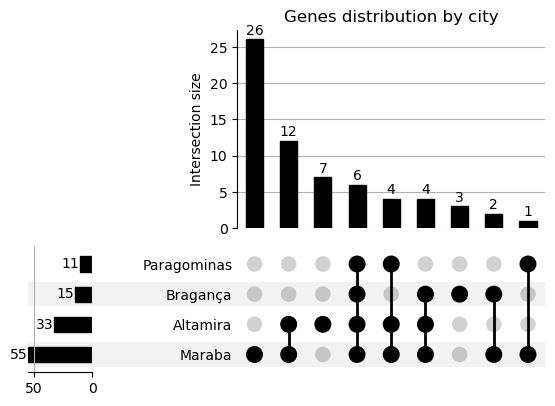

In [17]:
import pandas as pd
from upsetplot import UpSet, from_contents
import matplotlib.pyplot as plt


grouped_amgs = amgs_full.groupby('city')['gene_id'].apply(set)

sample_sets_amgs = grouped_amgs.to_dict()

upset_data_amgs = from_contents(sample_sets_amgs)


UpSet(upset_data_amgs, show_counts=True, sort_by='cardinality').plot()
plt.title("Genes distribution by city")
plt.show()


In [18]:
# Which amgs are present in all cities (most necessary in regard of environment)

altamira_set = grouped_amgs.loc['Altamira']
braganca_set = grouped_amgs.loc['Bragança']
maraba_set = grouped_amgs.loc['Maraba']
paragominas_set = grouped_amgs.loc['Paragominas']

result = maraba_set.intersection(altamira_set,braganca_set, paragominas_set)
print(result)

print(len(maraba_set))
print(len(altamira_set))
print(braganca_set)
print(paragominas_set)

{'K00525', 'K00560', 'GT2', 'U69', 'K01945', 'K00943'}
55
33
{'K01494', 'K00525', 'K00012', 'K09882', 'K00560', 'GT2', 'K02030', 'U69', 'K01992', 'K01945', 'K09883', 'K00943', 'K01845', 'K01666', 'K01939'}
{'K01637', 'K00525', 'C82A', 'K00560', 'M17', 'GT2', 'K00943', 'U69', 'K01945', 'K02040', 'K02639'}


In [19]:
#Unique from Maraba
unique_maraba = maraba_set.difference(altamira_set,braganca_set, paragominas_set)
print(len(unique_maraba))

#Unique from Altamira
unique_altamira = altamira_set.difference(maraba_set,braganca_set, paragominas_set)
print(unique_altamira)

#Unique from Bragança
unique_braganca = braganca_set.difference(maraba_set,altamira_set, paragominas_set)
print(unique_braganca)

#Unique from paragominas
unique_paragominas = paragominas_set.difference(maraba_set,braganca_set, altamira_set)
print(unique_paragominas)

26
{'M74', 'K00886', 'A28A', 'K01809', 'K10946', 'AA5', 'M01'}
{'K01992', 'K00012', 'K02030'}
set()


## Checking the "abundance" of each AMG classification by city 

In [20]:
amgs_full_test = amgs_full
amgs_full_test['header'] = amgs_full['header'].fillna(amgs_full['category'])

amgs_full_test['joined'] = amgs_full['joined'] = ( 
    amgs_full['scaffold'].astype(str) + ' | ' +
    amgs_full['gene_id'].astype(str) + ' | ' +
    amgs_full['category'].astype(str) + ' | ' +
    amgs_full['header'].astype(str) + ' | ' +
    amgs_full['subheader'].astype(str)
)

amgs_full_test = amgs_full_test.drop_duplicates(subset='joined', keep='first') # by doing it we are removeing any potential duplicated gene
amgs_full_test # the final dataset has 598 rows. This is because we are not removing genes that may contain mutiple funtions
amgs_full_test = amgs_full_test.drop('joined',axis=1)
amgs_full_test['header'].value_counts() / amgs_full_test['header'].value_counts().sum() * 100 #Percentages of each category

/MP_Data/database/rgi/wildcard/custom_tmp/ipykernel_3303244/2989314330.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  amgs_full_test['header'] = amgs_full['header'].fillna(amgs_full['category'])
/MP_Data/database/rgi/wildcard/custom_tmp/ipykernel_3303244/2989314330.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  amgs_full_test['joined'] = amgs_full['joined'] = (


header
Information systems              34.859155
Photosynthesis                   14.788732
Peptidase                        14.260563
central carbon                   10.035211
CAZY                              6.514085
Transporters                      6.161972
sugar utilization (woodcroft)     4.577465
aerobic corrin ring synthesis     2.464789
Amino Acid                        2.112676
ADO-CBL synthesis                 1.760563
C1                                0.880282
MISC                              0.528169
Antibiotic Resistance             0.528169
hydrocarbon degradation           0.352113
Nitrogen                          0.176056
Name: count, dtype: float64

In [21]:
maraba_count = amgs_full_test[amgs_full_test['city']== 'Maraba']['header'].value_counts().to_frame()
altamira_count = amgs_full_test[amgs_full_test['city']== 'Altamira']['header'].value_counts().to_frame()
braganca_count = amgs_full_test[amgs_full_test['city']== 'Bragança']['header'].value_counts().to_frame()
paragominas_count = amgs_full_test[amgs_full_test['city']== 'Paragominas']['header'].value_counts().to_frame()

In [22]:
import altair as alt

maraba_count = maraba_count.reset_index()
maraba_count = maraba_count.sort_values(by='count',ascending=False)
maraba_count.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/maraba_amg_cat.tsv',sep='\t')

mar_chart = alt.Chart(maraba_count).mark_bar().encode(
    alt.X('count:Q'),
    alt.Y('header:N', sort='-x'),
)
mar_chart

alt.Chart(...)

In [23]:
altamira_count = altamira_count.reset_index()
altamira_count = altamira_count.sort_values(by='count',ascending=False)
altamira_count.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/altamira_amg_cat.tsv',sep='\t')


alt_chart = alt.Chart(altamira_count).mark_bar().encode(
    alt.X('count:Q'),
    alt.Y('header:N', sort='-x'),
)
alt_chart

alt.Chart(...)

In [24]:
braganca_count = braganca_count.reset_index()
braganca_count = braganca_count.sort_values(by='count',ascending=False)
braganca_count.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/braganca_amg_cat.tsv',sep='\t')


bra_chart = alt.Chart(braganca_count).mark_bar().encode(
    alt.X('count:Q'),
    alt.Y('header:N', sort='-x'),
)
bra_chart

alt.Chart(...)

In [25]:
paragominas_count = paragominas_count.reset_index()
paragominas_count = paragominas_count.sort_values(by='count',ascending=False)
paragominas_count.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/paragominas_amg_cat.tsv',sep='\t')


par_chart = alt.Chart(paragominas_count).mark_bar().encode(
    alt.X('count:Q'),
    alt.Y('header:N', sort='-x'),
)
par_chart

alt.Chart(...)

# CHecking the unique functions per city

In [26]:
maraba_functions = set(maraba_count['header'])
braganca_functions = set(braganca_count['header'])
altamira_functions = set(altamira_count['header'])
paragominas_functions = set(paragominas_count['header'])

result_functions = maraba_functions.intersection(braganca_functions,altamira_functions,paragominas_functions)
result_functions

{'CAZY', 'Information systems', 'Peptidase', 'Transporters'}

/MP_Data/mambaforge/envs/bioinfokit/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/MP_Data/mambaforge/envs/bioinfokit/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["l

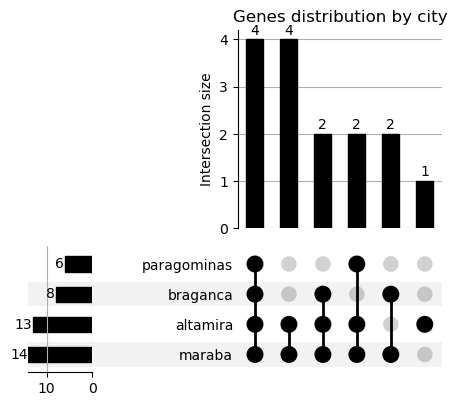

In [27]:
grouped_functions = {'altamira':altamira_functions,'maraba':maraba_functions,'paragominas':paragominas_functions,'braganca':braganca_functions}

upset_data_amgs = from_contents(grouped_functions)


UpSet(upset_data_amgs, show_counts=True, sort_by='cardinality').plot()
plt.title("Genes distribution by city")
plt.show()

In [28]:
altamira_functions.difference(braganca_functions,maraba_functions,paragominas_functions)

{'Nitrogen'}

## Number of vOTUs with AMGs

In [29]:
#amgs_full[['scaffold'].drop_duplicate()]

unique_scaffolds = set(amgs_full['scaffold'])
len(unique_scaffolds)

418

# Merging pAMGs with predicted host information

In [31]:
#Loading the host prediction information
hostpred = pd.read_csv("/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/05_host_prediction/iphop_results.tsv",sep='\t')
hostpred = hostpred[['Virus','Host taxonomy']]
hostpred

#Merging predicted amgs with predicted hosts

viral_hosts_plus_amgs = pd.merge(amgs_full, hostpred, left_on='scaffold', right_on='Virus', how='left')
viral_hosts_plus_amgs = viral_hosts_plus_amgs[viral_hosts_plus_amgs['Virus'].notna()]
viral_hosts_plus_amgs 

,scaffold,category,header,subheader,gene_id,gene_description,sample,city,joined,Virus,Host taxonomy
33,AP2_NODE_115_length_110076_cov_4.120456,Energy,Photosynthesis,NaN,K02703,psbA; photosystem II reaction center D1 protei...,AP2,Altamira,AP2_NODE_115_length_110076_cov_4.120456 | K027...,AP2_NODE_115_length_110076_cov_4.120456,d__Bacteria;p__Cyanobacteriota;c__Cyanobacteri...
36,AP2_NODE_1665_length_24119_cov_2.653301,Energy,Photosynthesis,NaN,K02703,psbA; photosystem II reaction center D1 protei...,AP2,Altamira,AP2_NODE_1665_length_24119_cov_2.653301 | K027...,AP2_NODE_1665_length_24119_cov_2.653301,d__Bacteria;p__Cyanobacteriota;c__Cyanobacteri...
45,AP2_NODE_25_length_217460_cov_4.397307,Energy,Photosynthesis,NaN,K02706,psbD; photosystem II reaction center D2 protei...,AP2,Altamira,AP2_NODE_25_length_217460_cov_4.397307 | K0270...,AP2_NODE_25_length_217460_cov_4.397307,d__Bacteria;p__Cyanobacteriota;c__Cyanobacteri...
46,AP2_NODE_25_length_217460_cov_4.397307,Energy,Photosynthesis,NaN,K02703,psbA; photosystem II reaction center D1 protei...,AP2,Altamira,AP2_NODE_25_length_217460_cov_4.397307 | K0270...,AP2_NODE_25_length_217460_cov_4.397307,d__Bacteria;p__Cyanobacteriota;c__Cyanobacteri...
47,AP2_NODE_25_length_217460_cov_4.397307,Energy,Photosynthesis,NaN,K02639,ferredoxin,AP2,Altamira,AP2_NODE_25_length_217460_cov_4.397307 | K0263...,AP2_NODE_25_length_217460_cov_4.397307,d__Bacteria;p__Cyanobacteriota;c__Cyanobacteri...
...,...,...,...,...,...,...,...,...,...,...,...
583,MP5_NODE_964_length_22790_cov_5.999824,Energy,Photosynthesis,NaN,K02703,psbA; photosystem II reaction center D1 protei...,MP5,Maraba,MP5_NODE_964_length_22790_cov_5.999824 | K0270...,MP5_NODE_964_length_22790_cov_5.999824,d__Bacteria;p__Cyanobacteriota;c__Cyanobacteri...
584,MP5_NODE_964_length_22790_cov_5.999824,Energy,Photosynthesis,NaN,K02639,ferredoxin,MP5,Maraba,MP5_NODE_964_length_22790_cov_5.999824 | K0263...,MP5_NODE_964_length_22790_cov_5.999824,d__Bacteria;p__Cyanobacteriota;c__Cyanobacteri...
585,MP5_NODE_98_length_89735_cov_3.992958,Energy,Photosynthesis,NaN,K02706,psbD; photosystem II reaction center D2 protei...,MP5,Maraba,MP5_NODE_98_length_89735_cov_3.992958 | K02706...,MP5_NODE_98_length_89735_cov_3.992958,d__Bacteria;p__Cyanobacteriota;c__Cyanobacteri...
594,PP1_NODE_959_length_16305_cov_1.227099,Energy,Photosynthesis,NaN,K02639,ferredoxin,PP1,Paragominas,PP1_NODE_959_length_16305_cov_1.227099 | K0263...,PP1_NODE_959_length_16305_cov_1.227099,d__Bacteria;p__Cyanobacteriota;c__Cyanobacteri...


## Getting number of vOTUs with both AMGs and predicted hosts

In [35]:
unique_votus_with_amgs_and_host = set(viral_hosts_plus_amgs['scaffold'])
len(unique_votus_with_amgs_and_host)

54

In [32]:
viral_hosts_plus_amgs = viral_hosts_plus_amgs.drop('Virus',axis=1)
viral_hosts_plus_amgs[['Domain',"Phylum", "Class", "Order", "Family", "Genus", "Species"]] = viral_hosts_plus_amgs['Host taxonomy'].str.split(';', n=7, expand = True)
viral_hosts_plus_amgs = viral_hosts_plus_amgs[['scaffold','gene_id','category','header','subheader', 'Phylum', 'Family']]


In [33]:
viral_hosts_plus_amgs['Phylum'].value_counts()

Phylum
p__Cyanobacteriota      56
p__Pseudomonadota       15
p__Bacillota             8
p__Thermoplasmatota      8
p__Verrucomicrobiota     6
p__Bacteroidota          4
p__Actinomycetota        1
p__Patescibacteriota     1
Name: count, dtype: int64

In [34]:
viral_hosts_plus_amgs['Family'].value_counts()

Family
f__Cyanobiaceae           32
f__Thalassarchaeaceae      8
f__Laspinemataceae         6
f__Phormidesmidaceae       6
f__Lachnospiraceae         6
f__Rhodocyclaceae          4
f__Terrimicrobiaceae       3
f__Coleofasciculaceae      3
f__Methylomonadaceae       3
f__MB11C04                 3
f__Alteromonadaceae        3
f__Leptolyngbyaceae        2
f__Prochlorotrichaceae     2
f__MRBY01                  2
f__Nostocaceae             2
f__Chitinophagaceae        2
f__LLD-282                 2
f__Pseudanabaenaceae       1
f__Enterobacteriaceae      1
f__Hyphomicrobiaceae       1
f__Cyclobacteriaceae       1
f__Rhizobiaceae            1
f__Rikenellaceae           1
f__Streptococcaceae        1
f__MedAcidi-G1             1
f__Nanosyncoccaceae        1
f__Lactobacillaceae        1
Name: count, dtype: int64

In [35]:
viral_hosts_plus_amgs['sample'] = viral_hosts_plus_amgs['scaffold'].apply(get_sample_name)
viral_hosts_plus_amgs['city'] = viral_hosts_plus_amgs['sample'].apply(define_city)
viral_hosts_plus_amgs['city'].value_counts()
viral_hosts_plus_amgs_phylum_grouped_counts = viral_hosts_plus_amgs.groupby('city')['Phylum'].value_counts()
viral_hosts_plus_amgs_phylum_grouped_counts.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/viral_hosts_plus_amgs_phylum_grouped_counts.tsv',sep='\t')
viral_hosts_plus_amgs_phylum_grouped_counts

city         Phylum              
Altamira     p__Cyanobacteriota      16
             p__Pseudomonadota        6
             p__Bacteroidota          2
Bragança     p__Pseudomonadota        1
Maraba       p__Cyanobacteriota      38
             p__Bacillota             8
             p__Pseudomonadota        8
             p__Thermoplasmatota      8
             p__Verrucomicrobiota     6
             p__Bacteroidota          2
             p__Actinomycetota        1
             p__Patescibacteriota     1
Paragominas  p__Cyanobacteriota       2
Name: count, dtype: int64

In [36]:
viral_hosts_plus_amgs_grouped_per_phylum = (
    viral_hosts_plus_amgs
    .groupby(['city', 'Phylum'])
    .apply(lambda x: x[['gene_id', 'category', 'header', 'subheader']].reset_index(drop=True))
    .reset_index(level=[0,1])
)
viral_hosts_plus_amgs_grouped_per_phylum.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/viral_hosts_plus_amgs_grouped_per_phylum.tsv',sep='\t')
viral_hosts_plus_amgs_grouped_per_phylum

/MP_Data/database/rgi/wildcard/custom_tmp/ipykernel_3303244/337729660.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x[['gene_id', 'category', 'header', 'subheader']].reset_index(drop=True))


,city,Phylum,gene_id,category,header,subheader
0,Altamira,p__Bacteroidota,K02040,Transporters,Transporters,NaN
1,Altamira,p__Bacteroidota,M17,Organic Nitrogen,Peptidase,NaN
0,Altamira,p__Cyanobacteriota,K02703,Energy,Photosynthesis,NaN
1,Altamira,p__Cyanobacteriota,K02703,Energy,Photosynthesis,NaN
2,Altamira,p__Cyanobacteriota,K02706,Energy,Photosynthesis,NaN
...,...,...,...,...,...,...
3,Maraba,p__Verrucomicrobiota,K02040,Transporters,Transporters,NaN
4,Maraba,p__Verrucomicrobiota,K00616,carbon utilization,central carbon,pentose pathway
5,Maraba,p__Verrucomicrobiota,K00616,carbon utilization,central carbon,pentose pathway
0,Paragominas,p__Cyanobacteriota,K02639,Energy,Photosynthesis,NaN


In [37]:
viral_hosts_plus_amgs_family_grouped_counts = viral_hosts_plus_amgs.groupby('city')['Family'].value_counts()
viral_hosts_plus_amgs_family_grouped_counts.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/viral_hosts_plus_amgs_family_grouped_counts.tsv',sep='\t')
viral_hosts_plus_amgs_family_grouped_counts

city         Family                
Altamira     f__Cyanobiaceae            8
             f__Laspinemataceae         4
             f__Alteromonadaceae        3
             f__Methylomonadaceae       3
             f__Chitinophagaceae        2
             f__Coleofasciculaceae      1
             f__Nostocaceae             1
             f__Prochlorotrichaceae     1
             f__Pseudanabaenaceae       1
Bragança     f__Enterobacteriaceae      1
Maraba       f__Cyanobiaceae           22
             f__Thalassarchaeaceae      8
             f__Lachnospiraceae         6
             f__Phormidesmidaceae       6
             f__Rhodocyclaceae          4
             f__MB11C04                 3
             f__Terrimicrobiaceae       3
             f__Coleofasciculaceae      2
             f__LLD-282                 2
             f__Laspinemataceae         2
             f__Leptolyngbyaceae        2
             f__MRBY01                  2
             f__Cyclobacteriaceae       

In [38]:
viral_hosts_plus_amgs_grouped_per_family = (
    viral_hosts_plus_amgs
    .groupby(['city', 'Family'])
    .apply(lambda x: x[['gene_id', 'category', 'header', 'subheader']].reset_index(drop=True))
    .reset_index(level=[0,1])
)
viral_hosts_plus_amgs_grouped_per_family.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/viral_hosts_plus_amgs_grouped_per_family.tsv',sep='\t')
viral_hosts_plus_amgs_grouped_per_family

/MP_Data/database/rgi/wildcard/custom_tmp/ipykernel_3303244/1044973546.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x[['gene_id', 'category', 'header', 'subheader']].reset_index(drop=True))


,city,Family,gene_id,category,header,subheader
0,Altamira,f__Alteromonadaceae,K01784,MISC,Information systems,Nucleotide
1,Altamira,f__Alteromonadaceae,K01784,carbon utilization,central carbon,glycolysis
2,Altamira,f__Alteromonadaceae,K01784,carbon utilization (Woodcroft),sugar utilization (woodcroft),galactose degradation
0,Altamira,f__Chitinophagaceae,K02040,Transporters,Transporters,NaN
1,Altamira,f__Chitinophagaceae,M17,Organic Nitrogen,Peptidase,NaN
...,...,...,...,...,...,...
5,Maraba,f__Thalassarchaeaceae,K00036,carbon utilization,central carbon,pentose pathway
6,Maraba,f__Thalassarchaeaceae,K00036,carbon utilization,central carbon,pentose pathway
7,Maraba,f__Thalassarchaeaceae,K00036,carbon utilization,central carbon,glycolysis
0,Paragominas,f__Cyanobiaceae,K02639,Energy,Photosynthesis,NaN


In [39]:
viral_hosts_plus_amgs_grouped_per_phylum_and_family = (
    viral_hosts_plus_amgs
    .groupby(['city','Family','Phylum'])
    .apply(lambda x: x[['gene_id', 'category', 'header', 'subheader']].reset_index(drop=True))
    .reset_index(level=[0,1,2])
)
#viral_hosts_plus_amgs_grouped_per_family.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/annotations_amgs/viral_hosts_plus_amgs_grouped_per_family.tsv',sep='\t')
viral_hosts_plus_amgs_grouped_per_phylum_and_family

/MP_Data/database/rgi/wildcard/custom_tmp/ipykernel_3303244/3269085712.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x[['gene_id', 'category', 'header', 'subheader']].reset_index(drop=True))


,city,Family,Phylum,gene_id,category,header,subheader
0,Altamira,f__Alteromonadaceae,p__Pseudomonadota,K01784,MISC,Information systems,Nucleotide
1,Altamira,f__Alteromonadaceae,p__Pseudomonadota,K01784,carbon utilization,central carbon,glycolysis
2,Altamira,f__Alteromonadaceae,p__Pseudomonadota,K01784,carbon utilization (Woodcroft),sugar utilization (woodcroft),galactose degradation
0,Altamira,f__Chitinophagaceae,p__Bacteroidota,K02040,Transporters,Transporters,NaN
1,Altamira,f__Chitinophagaceae,p__Bacteroidota,M17,Organic Nitrogen,Peptidase,NaN
...,...,...,...,...,...,...,...
5,Maraba,f__Thalassarchaeaceae,p__Thermoplasmatota,K00036,carbon utilization,central carbon,pentose pathway
6,Maraba,f__Thalassarchaeaceae,p__Thermoplasmatota,K00036,carbon utilization,central carbon,pentose pathway
7,Maraba,f__Thalassarchaeaceae,p__Thermoplasmatota,K00036,carbon utilization,central carbon,glycolysis
0,Paragominas,f__Cyanobiaceae,p__Cyanobacteriota,K02639,Energy,Photosynthesis,NaN


In [40]:
#Identifying how many scaffolds have a host predicted to each bacterial family
scaffold_counts = (
    viral_hosts_plus_amgs
    .groupby(['city','Family','Phylum'])['scaffold']
    .nunique()
    .reset_index(name='scaffold_count')
)
scaffold_counts.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/scaffold_count_with_amg_per_predhost.tsv', sep='\t')

# Making tables for the presence / absence of AMGs per bacterial host family divided by city

## Altamira

In [41]:
amgs_grouped_altamira = viral_hosts_plus_amgs_grouped_per_phylum_and_family[viral_hosts_plus_amgs_grouped_per_phylum_and_family['city'] == 'Altamira']
amgs_grouped_altamira = amgs_grouped_altamira[['Phylum','Family','header']]
amgs_grouped_altamira = amgs_grouped_altamira.groupby(['Phylum','Family'])['header'].value_counts().to_frame().reset_index()
amgs_grouped_altamira = pd.pivot_table(amgs_grouped_altamira, values='count', index=['Phylum','Family'], columns='header').fillna(0)
amgs_grouped_altamira

header                                      C1  Information systems  Nitrogen  \
Phylum             Family                                                       
p__Bacteroidota    f__Chitinophagaceae     0.0                  0.0       0.0   
p__Cyanobacteriota f__Coleofasciculaceae   0.0                  0.0       0.0   
                   f__Cyanobiaceae         0.0                  1.0       0.0   
                   f__Laspinemataceae      0.0                  0.0       0.0   
                   f__Nostocaceae          0.0                  0.0       0.0   
                   f__Prochlorotrichaceae  0.0                  0.0       0.0   
                   f__Pseudanabaenaceae    0.0                  1.0       0.0   
p__Pseudomonadota  f__Alteromonadaceae     0.0                  1.0       0.0   
                   f__Methylomonadaceae    1.0                  0.0       2.0   

header                                     Peptidase  Photosynthesis  \
Phylum             Family                                              
p__Bacteroidota    f__Chitinophagaceae           1.0             0.0   
p__Cyanobacteriota f__Coleofasciculaceae         0.0             1.0   
                   f__Cyanobiaceae               0.0             7.0   
                   f__Laspinemataceae            0.0             3.0   
                   f__Nostocaceae                0.0             1.0   
                   f__Prochlorotrichaceae        0.0             1.0   
                   f__Pseudanabaenaceae          0.0             0.0   
p__Pseudomonadota  f__Alteromonadaceae           0.0             0.0   
                   f__Methylomonadaceae          0.0             0.0   

header                                     Transporters  central carbon  \
Phylum             Family                                                 
p__Bacteroidota    f__Chitinophagaceae              1.0             0.0   
p__Cyanobacteriota f__Coleofasciculaceae            0.0             0.0   
                   f__Cyanobiaceae                  0.0             0.0   
                   f__Laspinemataceae               1.0             0.0   
                   f__Nostocaceae                   0.0             0.0   
                   f__Prochlorotrichaceae           0.0             0.0   
                   f__Pseudanabaenaceae             0.0             0.0   
p__Pseudomonadota  f__Alteromonadaceae              0.0             1.0   
                   f__Methylomonadaceae             0.0             0.0   

header                                     sugar utilization (woodcroft)  
Phylum             Family                                                 
p__Bacteroidota    f__Chitinophagaceae                               0.0  
p__Cyanobacteriota f__Coleofasciculaceae                             0.0  
                   f__Cyanobiaceae                                   0.0  
                   f__Laspinemataceae                                0.0  
                   f__Nostocaceae                                    0.0  
                   f__Prochlorotrichaceae                            0.0  
                   f__Pseudanabaenaceae                              0.0  
p__Pseudomonadota  f__Alteromonadaceae                               1.0  
                   f__Methylomonadaceae                              0.0

## Maraba

In [42]:
amgs_grouped_maraba = viral_hosts_plus_amgs_grouped_per_phylum_and_family[viral_hosts_plus_amgs_grouped_per_phylum_and_family['city'] == 'Maraba']
amgs_grouped_maraba = amgs_grouped_maraba[['Phylum','Family','header']]
amgs_grouped_maraba = amgs_grouped_maraba.groupby(['Phylum','Family'])['header'].value_counts().to_frame().reset_index()
amgs_grouped_maraba = pd.pivot_table(amgs_grouped_maraba, values='count', index=['Phylum','Family'], columns='header').fillna(0)
amgs_grouped_maraba

header                                       Amino Acid  CAZY  \
Phylum               Family                                     
p__Actinomycetota    f__MedAcidi-G1                 0.0   0.0   
p__Bacillota         f__Lachnospiraceae             0.0   0.0   
                     f__Lactobacillaceae            0.0   0.0   
                     f__Streptococcaceae            0.0   0.0   
p__Bacteroidota      f__Cyclobacteriaceae           0.0   0.0   
                     f__Rikenellaceae               0.0   1.0   
p__Cyanobacteriota   f__Coleofasciculaceae          0.0   0.0   
                     f__Cyanobiaceae                0.0   0.0   
                     f__Laspinemataceae             0.0   0.0   
                     f__Leptolyngbyaceae            0.0   0.0   
                     f__MRBY01                      0.0   0.0   
                     f__Nostocaceae                 0.0   0.0   
                     f__Phormidesmidaceae           0.0   0.0   
                     f__Prochlorotrichaceae         0.0   0.0   
p__Patescibacteriota f__Nanosyncoccaceae            0.0   0.0   
p__Pseudomonadota    f__Hyphomicrobiaceae           0.0   0.0   
                     f__LLD-282                     0.0   0.0   
                     f__Rhizobiaceae                0.0   0.0   
                     f__Rhodocyclaceae              0.0   0.0   
p__Thermoplasmatota  f__Thalassarchaeaceae          1.0   0.0   
p__Verrucomicrobiota f__MB11C04                     0.0   0.0   
                     f__Terrimicrobiaceae           0.0   0.0   

header                                       Information systems  MISC  \
Phylum               Family                                              
p__Actinomycetota    f__MedAcidi-G1                          0.0   0.0   
p__Bacillota         f__Lachnospiraceae                      2.0   1.0   
                     f__Lactobacillaceae                     1.0   0.0   
                     f__Streptococcaceae                     0.0   0.0   
p__Bacteroidota      f__Cyclobacteriaceae                    1.0   0.0   
                     f__Rikenellaceae                        0.0   0.0   
p__Cyanobacteriota   f__Coleofasciculaceae                   0.0   0.0   
                     f__Cyanobiaceae                         1.0   0.0   
                     f__Laspinemataceae                      0.0   0.0   
                     f__Leptolyngbyaceae                     0.0   0.0   
                     f__MRBY01                               0.0   0.0   
                     f__Nostocaceae                          1.0   0.0   
                     f__Phormidesmidaceae                    0.0   0.0   
                     f__Prochlorotrichaceae                  0.0   0.0   
p__Patescibacteriota f__Nanosyncoccaceae                     0.0   0.0   
p__Pseudomonadota    f__Hyphomicrobiaceae                    1.0   0.0   
                     f__LLD-282                              0.0   0.0   
                     f__Rhizobiaceae                         0.0   0.0   
                     f__Rhodocyclaceae                       1.0   0.0   
p__Thermoplasmatota  f__Thalassarchaeaceae                   0.0   0.0   
p__Verrucomicrobiota f__MB11C04                              0.0   0.0   
                     f__Terrimicrobiaceae                    0.0   0.0   

header                                       Peptidase  Photosynthesis  \
Phylum               Family                                              
p__Actinomycetota    f__MedAcidi-G1                0.0             1.0   
p__Bacillota         f__Lachnospiraceae            1.0             0.0   
                     f__Lactobacillaceae           0.0             0.0   
                     f__Streptococcaceae           0.0             1.0   
p__Bacteroidota      f__Cyclobacteriaceae          0.0             0.0   
                     f__Rikenellaceae              0.0             0.0   
p__Cyanobacteriota   f__Coleofasciculaceae         0.0             2.0

## Bragança

In [43]:
amgs_grouped_braganca = viral_hosts_plus_amgs_grouped_per_phylum_and_family[viral_hosts_plus_amgs_grouped_per_phylum_and_family['city'] == 'Bragança']
amgs_grouped_braganca = amgs_grouped_braganca[['Phylum','Family','header']]
amgs_grouped_braganca = amgs_grouped_braganca.groupby(['Phylum','Family'])['header'].value_counts().to_frame().reset_index()
amgs_grouped_braganca = pd.pivot_table(amgs_grouped_braganca, values='count', index=['Phylum','Family'], columns='header').fillna(0)
amgs_grouped_braganca

,header,Transporters
Phylum,Family,
p__Pseudomonadota,f__Enterobacteriaceae,1.0


## Paragominas

In [44]:
amgs_grouped_paragominas = viral_hosts_plus_amgs_grouped_per_phylum_and_family[viral_hosts_plus_amgs_grouped_per_phylum_and_family['city'] == 'Paragominas']
amgs_grouped_paragominas = amgs_grouped_paragominas[['Phylum','Family','header']]
amgs_grouped_paragominas = amgs_grouped_paragominas.groupby(['Phylum','Family'])['header'].value_counts().to_frame().reset_index()
amgs_grouped_paragominas = pd.pivot_table(amgs_grouped_paragominas, values='count', index=['Phylum','Family'], columns='header').fillna(0)
amgs_grouped_paragominas

,header,Photosynthesis,Transporters
Phylum,Family,,
p__Cyanobacteriota,f__Cyanobiaceae,1.0,1.0


In [45]:
amgs_grouped_altamira = amgs_grouped_altamira.reset_index()
amgs_grouped_altamira['city'] = 'altamira'
amgs_grouped_maraba = amgs_grouped_maraba.reset_index()
amgs_grouped_maraba['city'] = 'maraba'
amgs_grouped_braganca = amgs_grouped_braganca.reset_index()
amgs_grouped_braganca['city'] = 'braganca'
amgs_grouped_paragominas = amgs_grouped_paragominas.reset_index()
amgs_grouped_paragominas['city'] = 'paragominas'

concatenated_dfs = pd.concat([amgs_grouped_altamira,amgs_grouped_maraba,amgs_grouped_braganca,amgs_grouped_paragominas]).fillna(0)
#concatenated_dfs = concatenated_dfs.drop('header',axis=1)
concatenated_dfs = concatenated_dfs.set_index(['city','Phylum','Family'])
concatenated_dfs.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/03_annotation/processed_tables/amgs_plus_iphop_combined.tsv',sep='\t')
concatenated_dfs

header                                                    C1  \
city        Phylum               Family                        
altamira    p__Bacteroidota      f__Chitinophagaceae     0.0   
            p__Cyanobacteriota   f__Coleofasciculaceae   0.0   
                                 f__Cyanobiaceae         0.0   
                                 f__Laspinemataceae      0.0   
                                 f__Nostocaceae          0.0   
                                 f__Prochlorotrichaceae  0.0   
                                 f__Pseudanabaenaceae    0.0   
            p__Pseudomonadota    f__Alteromonadaceae     0.0   
                                 f__Methylomonadaceae    1.0   
maraba      p__Actinomycetota    f__MedAcidi-G1          0.0   
            p__Bacillota         f__Lachnospiraceae      0.0   
                                 f__Lactobacillaceae     0.0   
                                 f__Streptococcaceae     0.0   
            p__Bacteroidota      f__Cyclobacteriaceae    0.0   
                                 f__Rikenellaceae        0.0   
            p__Cyanobacteriota   f__Coleofasciculaceae   0.0   
                                 f__Cyanobiaceae         0.0   
                                 f__Laspinemataceae      0.0   
                                 f__Leptolyngbyaceae     0.0   
                                 f__MRBY01               0.0   
                                 f__Nostocaceae          0.0   
                                 f__Phormidesmidaceae    0.0   
                                 f__Prochlorotrichaceae  0.0   
            p__Patescibacteriota f__Nanosyncoccaceae     0.0   
            p__Pseudomonadota    f__Hyphomicrobiaceae    0.0   
                                 f__LLD-282              0.0   
                                 f__Rhizobiaceae         0.0   
                                 f__Rhodocyclaceae       0.0   
            p__Thermoplasmatota  f__Thalassarchaeaceae   0.0   
            p__Verrucomicrobiota f__MB11C04              0.0   
                                 f__Terrimicrobiaceae    0.0   
braganca    p__Pseudomonadota    f__Enterobacteriaceae   0.0   
paragominas p__Cyanobacteriota   f__Cyanobiaceae         0.0   

header                                                   Information systems  \
city        Phylum               Family                                        
altamira    p__Bacteroidota      f__Chitinophagaceae                     0.0   
            p__Cyanobacteriota   f__Coleofasciculaceae                   0.0   
                                 f__Cyanobiaceae                         1.0   
                                 f__Laspinemataceae                      0.0   
                                 f__Nostocaceae                          0.0   
                                 f__Prochlorotrichaceae                  0.0   
                                 f__Pseudanabaenaceae                    1.0   
            p__Pseudomonadota    f__Alteromonadaceae                     1.0   
                                 f__Methylomonadaceae                    0.0   
maraba      p__Actinomycetota    f__MedAcidi-G1                          0.0   
            p__Bacillota         f__Lachnospiraceae                      2.0   
                                 f__Lactobacillaceae                     1.0   
                                 f__Streptococcaceae                     0.0   
            p__Bacteroidota      f__Cyclobacteriaceae                    1.0   
                                 f__Rikenellaceae                        0.0   
            p__Cyanobacteriota   f__Coleofasciculaceae                   0.0   
                                 f__Cyanobiaceae                         1.0   
                                 f__Laspinemataceae                      0.0   
                                 f__Leptolyngbyaceae                     0.0   
                                 f__MRBY01                               0.0   

# Making sankey for hosts and AMG content

In [63]:
host_amg_sankey = concatenated_dfs
host_amg_sankey = host_amg_sankey.reset_index()
host_amg_sankey = host_amg_sankey.drop(['city','Phylum'],axis=1)
host_amg_sankey = host_amg_sankey.groupby('Family').sum()
host_amg_sankey = host_amg_sankey.reset_index() 
host_amg_sankey_melted = pd.melt(host_amg_sankey , 
                                 id_vars="Family",  var_name='amg_content', value_name='count', col_level=None, ignore_index=True)
host_amg_sankey_melted = host_amg_sankey_melted[host_amg_sankey_melted['count'] > 0]
host_amg_sankey_melted

,Family,amg_content,count
15,f__Methylomonadaceae,C1,1.0
27,f__Alteromonadaceae,Information systems,1.0
30,f__Cyanobiaceae,Information systems,2.0
31,f__Cyclobacteriaceae,Information systems,1.0
33,f__Hyphomicrobiaceae,Information systems,1.0
35,f__Lachnospiraceae,Information systems,2.0
36,f__Lactobacillaceae,Information systems,1.0
44,f__Nostocaceae,Information systems,1.0
47,f__Pseudanabaenaceae,Information systems,1.0
49,f__Rhodocyclaceae,Information systems,1.0


# Evaluating if the AMGs are differentially enriched depending on the river 

In [46]:
maraba_n_amgs = unique_contigs[unique_contigs['city'] == 'Maraba']['gene_id'].count()
altamira_n_amgs = unique_contigs[unique_contigs['city'] == 'Altamira']['gene_id'].count()
braganca_n_amgs = unique_contigs[unique_contigs['city'] == 'Bragança']['gene_id'].count()
paragominas_n_amgs = unique_contigs[unique_contigs['city'] == 'Paragominas']['gene_id'].count()

maraba_n_genes = dramv[dramv['city'] == 'Maraba']['final_annotation'].count()
altamira_n_genes = dramv[dramv['city'] == 'Altamira']['final_annotation'].count()
braganca_n_genes = dramv[dramv['city'] == 'Bragança']['final_annotation'].count()
paragominas_n_genes = dramv[dramv['city'] == 'Paragominas']['final_annotation'].count()

print(maraba_n_amgs, altamira_n_amgs, braganca_n_amgs, paragominas_n_amgs)
print(maraba_n_genes, altamira_n_genes, braganca_n_genes, paragominas_n_genes)


323 142 20 28
47620 24248 5131 6540


In [47]:
import numpy as np
from rpy2.robjects import r, numpy2ri
import rpy2.robjects as ro


table = np.array([
    [maraba_n_amgs, (maraba_n_genes - maraba_n_amgs)],  # amostra 1: 12 sucessos, 88 fracassos
    [altamira_n_amgs, (altamira_n_genes - altamira_n_amgs)],  # amostra 2
    [braganca_n_amgs, (braganca_n_genes - braganca_n_amgs)],  # amostra 3
    [paragominas_n_amgs, (paragominas_n_genes - paragominas_n_amgs)],  # amostra 4
], dtype=object)  # <- ESSENCIAL!

# Converter cada valor para int nativo
table = table.astype(object)

# Criar matriz do R manulamente
r_matrix = ro.r.matrix(ro.IntVector([int(x) for x in table.flatten()]),
                       nrow=table.shape[0],
                       byrow=True)

# Rodar Fisher com mais workspace
resultado = r['fisher.test'](r_matrix, workspace=2e8)


print(resultado)


	Fisher's Exact Test for Count Data

data:  structure(c(323L, 142L, 20L, 28L, 47297L, 24106L, 5111L, 6512L), dim = c(4L, 2L))
p-value = 0.008337
alternative hypothesis: two.sided




# Extraindo o total de AMGs por cidade e o total de anotações por cidade

# Making hypergeometric comparisons between the samples number of amgs and the total dataset of amgs

In [ ]:
from scipy.stats import hypergeom
import itertools

groups = {
    "maraba": {"k": 323, "N": 49822},
    "altamira": {"k": 142, "N": 26590},
    "braganca": {"k": 28,  "N": 5287},
    "paragominas": {"k": 20,  "N": 6895}
}


def hypergeom_test(g):
    N_city = groups[g]["N"] #Total de anotaççoes da cidade
    M  = maraba_n_genes + altamira_n_genes + braganca_n_genes + paragominas_n_genes #Total de genes do dataset
    k_city = groups[g]["k"] # Number of amgs in that city
    n = maraba_n_amgs + altamira_n_amgs + braganca_n_amgs + paragominas_n_amgs #Total de amgs do dataset

    p = hypergeom.sf(k_city - 1, M, n, N_city)
    return p

for city in groups.keys():
    p = hypergeom_test(city)
    print(f"The p-value for {city} is {p}")

The p-value for maraba is 0.012906104979082561
The p-value for altamira is 0.7394663481972323
The p-value for braganca is 0.9702381228738469
The p-value for paragominas is 0.9901585273829101


- We fail to reject the null hypothesis for maraba 
- Therefore, Marabá truly has more AMGs than expected relative to the global background.

# Merging AMGs and life mode

In [53]:
life_mode_df = pd.read_csv('/MP_Data/Dados_David/viral_analysis/post_processing/votus_definition/life_mode_pred/scaffolds_life_mode_pred.tsv',sep='\t')

amgs_plus_LM = pd.merge(amgs_full, life_mode_df, left_on='scaffold', right_on='Accession', how='left')
amgs_plus_LM[amgs_plus_LM['final_classification'] == 'Litic']['header'].value_counts()

header
Information systems              142
Photosynthesis                    79
Peptidase                         60
central carbon                    57
Transporters                      30
CAZY                              28
sugar utilization (woodcroft)     21
ADO-CBL synthesis                 16
Amino Acid                        15
aerobic corrin ring synthesis      8
C1                                 7
MISC                               3
Nitrogen                           2
Antibiotic Resistance              1
Name: count, dtype: int64

In [54]:
amgs_plus_LM[amgs_plus_LM['final_classification'] == 'Lysogenic']['header'].value_counts()

header
Information systems    7
Peptidase              2
CAZY                   2
Transporters           1
Photosynthesis         1
Name: count, dtype: int64

# Merging AMGs, life mode and hosts

In [55]:
viral_hosts_plus_amgs_plus_LM = pd.merge(viral_hosts_plus_amgs, life_mode_df, left_on='scaffold', right_on='Accession', how='left')
viral_hosts_plus_amgs_plus_LM[viral_hosts_plus_amgs_plus_LM['final_classification'] == 'Lysogenic']

,scaffold,gene_id,category,header,subheader,Phylum,Family,sample,city,Unnamed: 0,Accession,final_classification
24,BP4_NODE_427_length_31949_cov_19.343795,K01992,Transporters,Transporters,NaN,p__Pseudomonadota,f__Enterobacteriaceae,BP4,Bragança,2225.0,BP4_NODE_427_length_31949_cov_19.343795,Lysogenic
25,MP1_NODE_330_length_58197_cov_2.696539,K01494,MISC,Information systems,Nucleotide,p__Pseudomonadota,f__Hyphomicrobiaceae,MP1,Maraba,2338.0,MP1_NODE_330_length_58197_cov_2.696539,Lysogenic
